In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from scipy import signal as sps

from src.data.constants import ALL_RECORDS, PACED_RECORDS, DS1, DS2, FS
from src.data.loader import load_record, build_beat_table
from src.preprocessing.filters import clean_ecg, design_bandpass
from src.preprocessing.normalization import robust_scale_record
from src.preprocessing.rpeaks import detect_r_peaks, evaluate_detection
from src.preprocessing.segmentation import extract_windows, rr_features

sns.set_theme(style="whitegrid")
CFG = yaml.safe_load((PROJECT_ROOT / "configs" / "preprocessing.yaml").read_text(encoding="utf-8"))
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "mitdb"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

F = CFG["filter"]
def filt(x):
    return clean_ecg(x, FS, F["low_hz"], F["high_hz"], F["order"], F["notch_hz"])

USABLE = [r for r in ALL_RECORDS if r not in PACED_RECORDS]
raw = {rid: load_record(rid, DATA_DIR).signal for rid in USABLE}
_, beats = build_beat_table(USABLE, DATA_DIR)
print(len(USABLE), "records |", len(beats), "battements annotés (Q inclus)")

44 records | 100733 battements annotés (Q inclus)


In [2]:
def band_ratio(x, lo, hi):
    f, p = sps.welch(x.astype(np.float64), fs=FS, nperseg=4096)
    sel = (f >= lo) & (f < hi)
    return p[sel].sum() / p.sum()

bands = {"derive_<0.5Hz": (0, 0.5), "secteur_58-62Hz": (58, 62), "HF_>40Hz": (40, 180)}
noise = pd.DataFrame({rid: {k: band_ratio(x, *b) for k, b in bands.items()}
                      for rid, x in raw.items()}).T
print(noise.describe().round(5))
for col in noise.columns:
    print(f"{col:>18} -> 5 records les plus touchés :", noise[col].nlargest(5).index.tolist())

       derive_<0.5Hz  secteur_58-62Hz  HF_>40Hz
count       44.00000         44.00000  44.00000
mean         0.15363          0.00057   0.00358
std          0.13790          0.00061   0.00311
min          0.01044          0.00001   0.00045
25%          0.05121          0.00005   0.00158
50%          0.11299          0.00042   0.00258
75%          0.22063          0.00096   0.00424
max          0.62143          0.00289   0.01412
     derive_<0.5Hz -> 5 records les plus touchés : ['108', '121', '222', '111', '219']
   secteur_58-62Hz -> 5 records les plus touchés : ['222', '215', '111', '100', '212']
          HF_>40Hz -> 5 records les plus touchés : ['100', '222', '212', '209', '220']


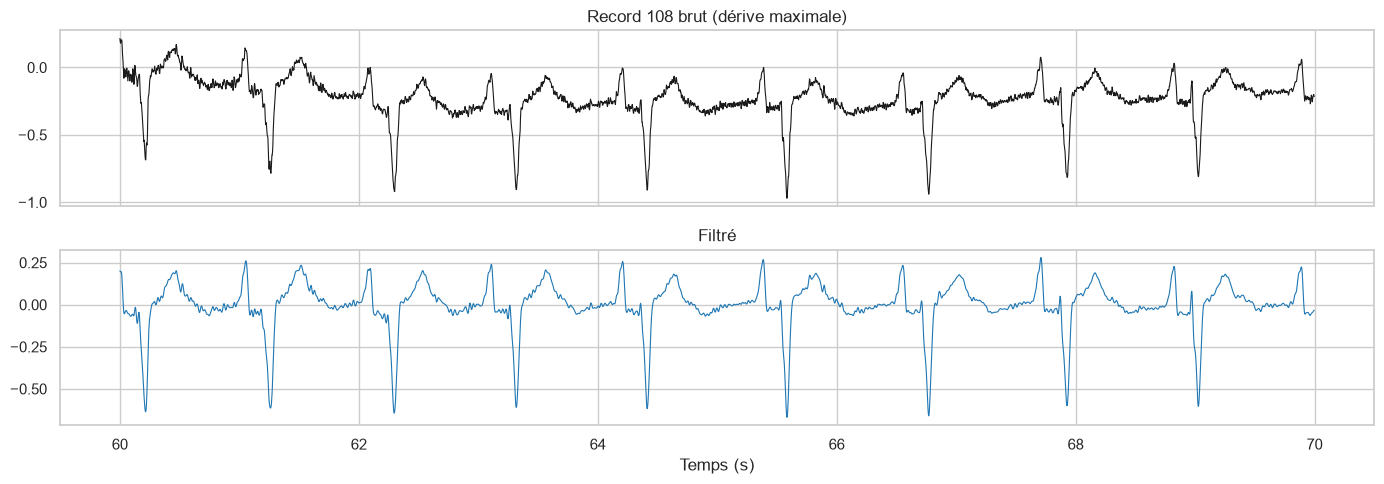

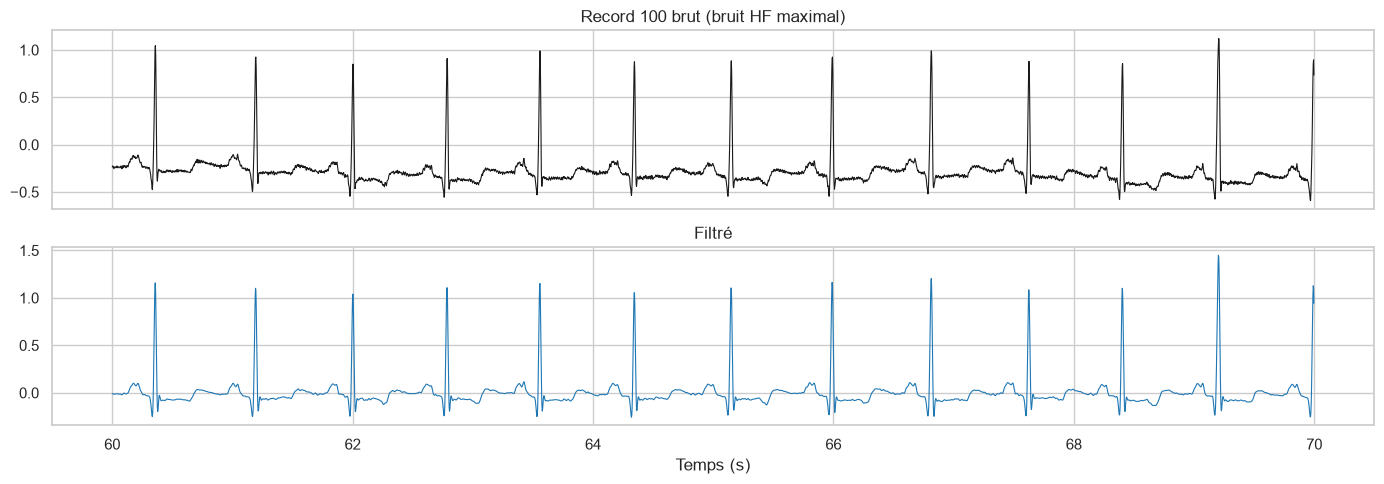

In [3]:
def plot_before_after(rid, start_s=60, dur_s=10, title=""):
    x = raw[rid]; y = filt(x)
    sl = slice(int(start_s * FS), int((start_s + dur_s) * FS))
    t = np.arange(len(x))[sl] / FS
    fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
    ax[0].plot(t, x[sl], lw=0.8, color="k"); ax[0].set_title(f"Record {rid} brut {title}")
    ax[1].plot(t, y[sl], lw=0.8, color="tab:blue"); ax[1].set_title("Filtré")
    ax[1].set_xlabel("Temps (s)"); plt.tight_layout(); return fig

rid_drift = noise["derive_<0.5Hz"].idxmax()
rid_hf = noise["HF_>40Hz"].idxmax()
plot_before_after(rid_drift, title="(dérive maximale)").savefig(FIG_DIR / "filter_drift.png", dpi=150)
plot_before_after(rid_hf, title="(bruit HF maximal)").savefig(FIG_DIR / "filter_hf.png", dpi=150)

  0.1 Hz :  -112.6 dB
  0.5 Hz :    -6.0 dB
    5 Hz :     0.0 dB
   25 Hz :    -0.1 dB
   40 Hz :    -6.0 dB
   60 Hz :   -32.8 dB


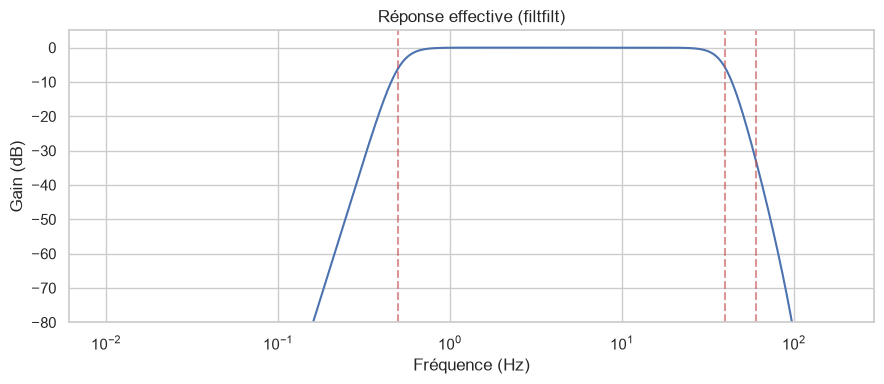

In [4]:
sos = design_bandpass(F["low_hz"], F["high_hz"], FS, F["order"])
w, h = sps.sosfreqz(sos, worN=np.logspace(-2, np.log10(FS / 2 - 1), 3000), fs=FS)
gain_db = 2 * 20 * np.log10(np.abs(h) + 1e-12)   # x2 : filtfilt élève |H| au carré

plt.figure(figsize=(9, 4)); plt.semilogx(w, gain_db)
for fx in (F["low_hz"], F["high_hz"], 60): plt.axvline(fx, ls="--", c="r", alpha=0.6)
plt.ylim(-80, 5); plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.title("Réponse effective (filtfilt)"); plt.tight_layout()
for f0 in [0.1, 0.5, 5, 25, 40, 60]:
    print(f"{f0:>5} Hz : {np.interp(f0, w, gain_db):7.1f} dB")

In [5]:
x, y = raw["100"], filt(raw["100"])
s = beats[beats.record_id == "100"]["sample"].to_numpy()
s = s[(s > FS) & (s < len(x) - FS)]

def peak_amp(sig):
    return np.array([np.abs(sig[i - 10: i + 11] - np.median(sig[i - FS // 2: i + FS // 2])).max()
                     for i in s])

ratio = peak_amp(y) / peak_amp(x)
print("Amplitude du QRS après/avant filtrage (quantiles 5/50/95 %) :",
      np.percentile(ratio, [5, 50, 95]).round(3))

Amplitude du QRS après/avant filtrage (quantiles 5/50/95 %) : [0.911 0.945 0.997]


Plus faible amplitude : 222 (0.130) | plus forte : 213 (0.631)
   méthode  taille QRS (propre)  taille QRS (avec artefact)
0  z-score               6.7815                      6.7767
1  min-max               0.2693                      0.1542
2  robuste              12.4386                     12.4386


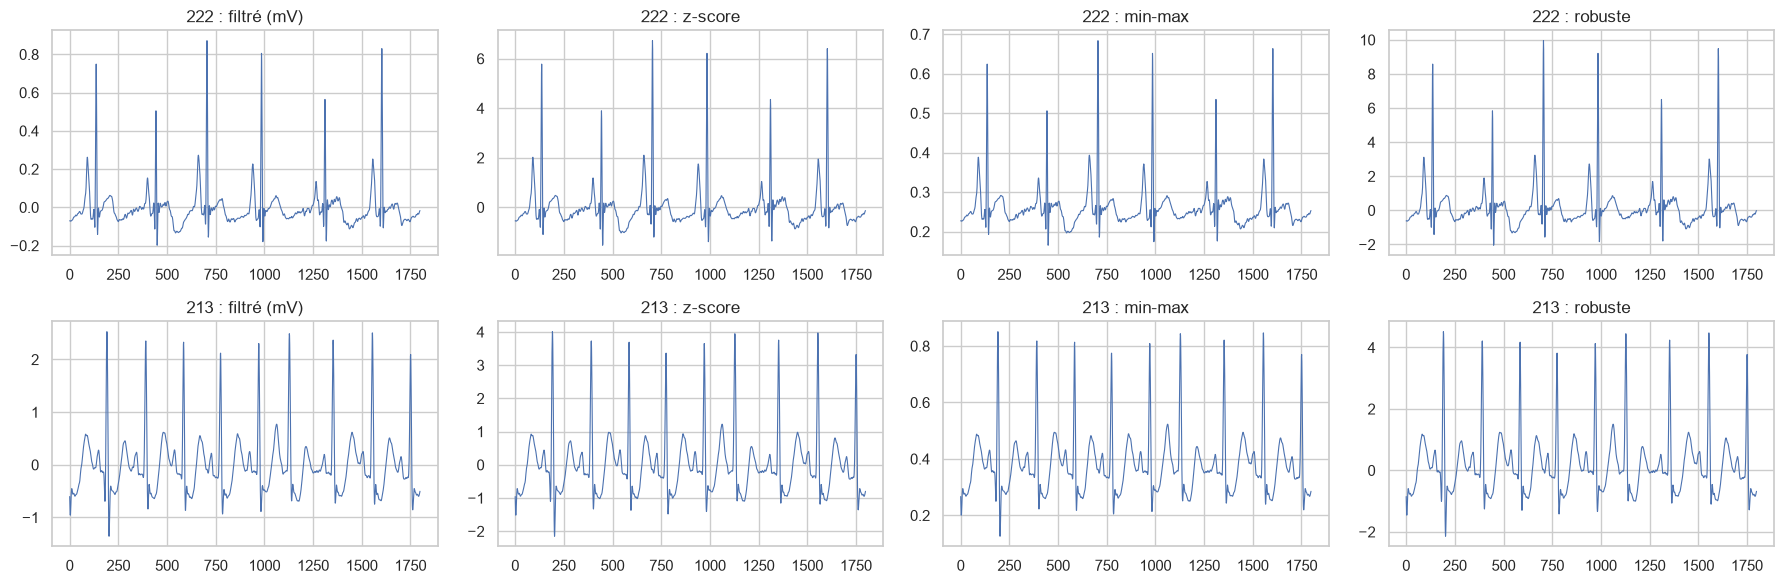

In [6]:
sd = pd.Series({rid: filt(x).std() for rid, x in raw.items()})
lo_rid, hi_rid = sd.idxmin(), sd.idxmax()
print(f"Plus faible amplitude : {lo_rid} ({sd.min():.3f}) | plus forte : {hi_rid} ({sd.max():.3f})")

def zscore(x): return (x - x.mean()) / x.std()
def minmax(x): return (x - x.min()) / (x.max() - x.min())
methods = {"filtré (mV)": lambda x: x, "z-score": zscore, "min-max": minmax,
           "robuste": lambda x: robust_scale_record(x).astype(np.float64)}

fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for r, rid in enumerate([lo_rid, hi_rid]):
    y = filt(raw[rid]).astype(np.float64)
    for c, (name, fn) in enumerate(methods.items()):
        axes[r, c].plot(fn(y)[60 * FS: 65 * FS], lw=0.8)
        axes[r, c].set_title(f"{rid} : {name}")
plt.tight_layout(); fig.savefig(FIG_DIR / "normalization_compare.png", dpi=150)

# Robustesse : on ajoute un artefact SYNTHÉTIQUE (volontairement fabriqué pour ce test)
y = filt(raw["100"]).astype(np.float64)
y_sp = y.copy(); y_sp[5000] += 30 * y.std()
s = beats[beats.record_id == "100"]["sample"].to_numpy()
def qrs_size(z): return np.median(np.abs(z[s] - np.median(z)))
rows = [{"méthode": n, "taille QRS (propre)": qrs_size(fn(y)),
         "taille QRS (avec artefact)": qrs_size(fn(y_sp))}
        for n, fn in methods.items() if n != "filtré (mV)"]
print(pd.DataFrame(rows).round(4))

            ref   det    TP   FP  FN  sens_%   ppv_%
record_id                                           
201        1963  2071  1938  133  25   98.73   93.58
116        2412  2393  2390    3  22   99.09   99.87
210        2650  2640  2629   11  21   99.21   99.58
203        2980  2996  2958   38  22   99.26   98.73
208        2955  2963  2940   23  15   99.49   99.22
124        1619  1611  1611    0   8   99.51  100.00
223        2605  2594  2594    0  11   99.58  100.00
202        2136  2163  2129   34   7   99.67   98.43

Global : sensibilité = 99.82 % | PPV = 91.96 %


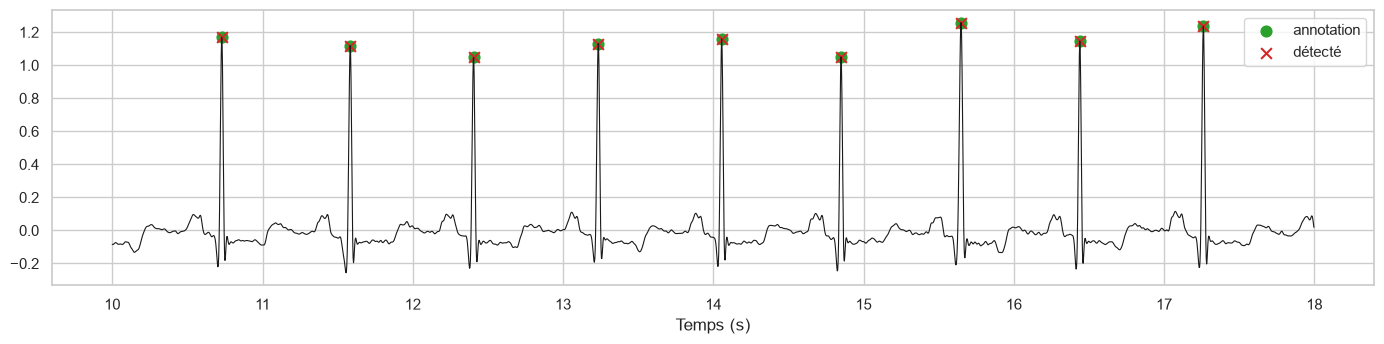

In [7]:
tol = int(0.150 * FS)          # tolérance EC57 : 150 ms
rows = []
for rid in USABLE:
    ref = beats[beats.record_id == rid]["sample"].to_numpy()
    det = detect_r_peaks(filt(raw[rid]), FS)
    tp, fp, fn = evaluate_detection(ref, det, tol)
    rows.append({"record_id": rid, "ref": len(ref), "det": len(det), "TP": tp, "FP": fp,
                 "FN": fn, "sens_%": 100 * tp / max(tp + fn, 1), "ppv_%": 100 * tp / max(tp + fp, 1)})
det_df = pd.DataFrame(rows).set_index("record_id")
tot = det_df[["TP", "FP", "FN"]].sum()
print(det_df.sort_values("sens_%").head(8).round(2))
print(f"\nGlobal : sensibilité = {100*tot.TP/(tot.TP+tot.FN):.2f} % | PPV = {100*tot.TP/(tot.TP+tot.FP):.2f} %")
  
rid = "100"; x = filt(raw[rid]); det = detect_r_peaks(x, FS)
ref = beats[beats.record_id == rid]["sample"].to_numpy()
sl = slice(10 * FS, 18 * FS); t = np.arange(len(x))[sl] / FS
plt.figure(figsize=(14, 3.6)); plt.plot(t, x[sl], "k", lw=0.8)
r_ = ref[(ref >= sl.start) & (ref < sl.stop)]; d_ = det[(det >= sl.start) & (det < sl.stop)]
plt.scatter(r_ / FS, x[r_], c="tab:green", s=60, label="annotation")
plt.scatter(d_ / FS, x[d_], c="tab:red", marker="x", s=60, label="détecté"); plt.legend()
plt.xlabel("Temps (s)"); plt.tight_layout()

      rr_prev_median_s  pct_R_precedent_dans_fenetre  \
aami                                                   
F                 0.59                           0.0   
N                 0.76                           0.0   
S                 0.49                           0.0   
V                 0.52                           0.0   

      pct_R_suivant_dans_fenetre  
aami                              
F                           0.24  
N                           0.02  
S                           0.00  
V                           0.84  


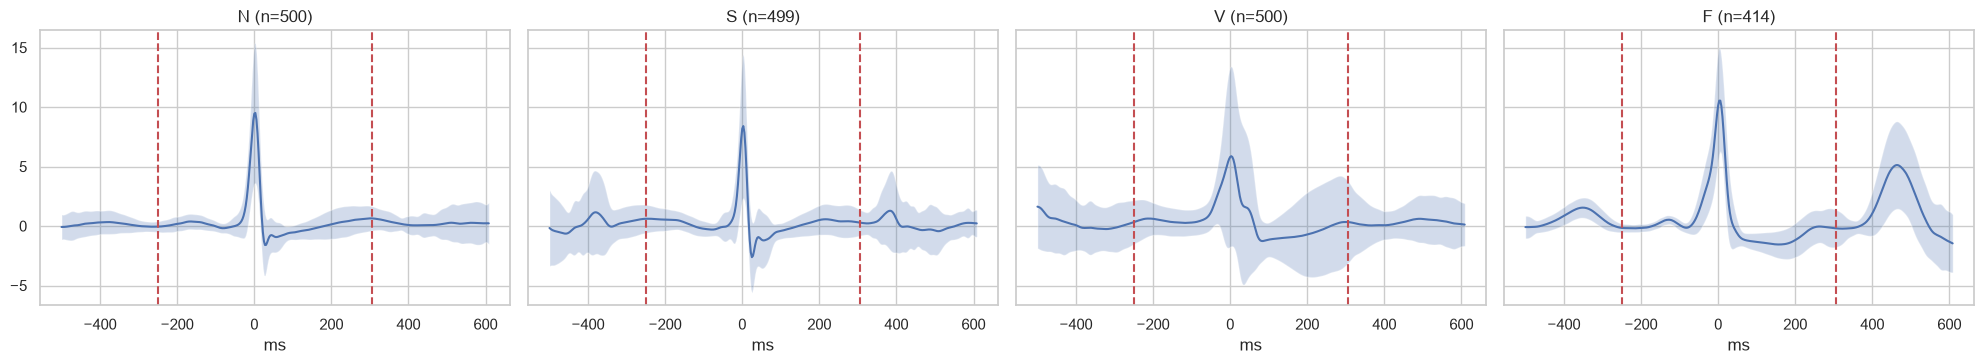

In [8]:
PRE_W, POST_W = 180, 220
norm_sig = {rid: robust_scale_record(filt(raw[rid])) for rid in DS1}
ds1_beats = beats[beats.record_id.isin(DS1) & beats.aami.isin(CFG["classes"])]
t = np.arange(-PRE_W, POST_W) / FS * 1000

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, cls in zip(axes, CFG["classes"]):
    sub = ds1_beats[ds1_beats.aami == cls]
    sub = sub.sample(n=min(500, len(sub)), random_state=CFG["seed"])
    Ws = [extract_windows(norm_sig[rid], g["sample"].to_numpy(), PRE_W, POST_W)[0]
          for rid, g in sub.groupby("record_id")]
    W = np.concatenate(Ws); m, s_ = W.mean(0), W.std(0)
    ax.plot(t, m); ax.fill_between(t, m - s_, m + s_, alpha=0.25)
    for edge in (-CFG["window"]["pre"], CFG["window"]["post"]):
        ax.axvline(edge / FS * 1000, ls="--", c="r")
    ax.set_title(f"{cls} (n={len(W)})"); ax.set_xlabel("ms")
plt.tight_layout(); fig.savefig(FIG_DIR / "window_choice.png", dpi=150)

rr_rows = []
for rid, g in beats[beats.record_id.isin(DS1)].groupby("record_id"):
    rr = rr_features(g["sample"].to_numpy(), FS, CFG["rr_local_n"])
    rr_rows.append(g.assign(rr_prev=rr["rr_prev"], rr_next=rr["rr_next"]))
rrdf = pd.concat(rr_rows); rrdf = rrdf[rrdf.aami.isin(CFG["classes"])]
print(rrdf.groupby("aami").agg(
    rr_prev_median_s=("rr_prev", "median"),
    pct_R_precedent_dans_fenetre=("rr_prev", lambda s: 100 * (s * FS < CFG["window"]["pre"]).mean()),
    pct_R_suivant_dans_fenetre=("rr_next", lambda s: 100 * (s * FS < CFG["window"]["post"]).mean())).round(2))

In [9]:
d = np.load(PROJECT_ROOT / CFG["output"]["dataset"])
for k in d.files:
    print(f"{k:10s}", d[k].shape, d[k].dtype)
meta = pd.read_csv(PROJECT_ROOT / CFG["output"]["meta"], dtype={"record_id": str})
print(meta.head())

X          (100690, 200) float32
y          (100690,) int8
record_id  (100690,) <U3
sample     (100690,) int32
symbol     (100690,) <U1
rr_prev    (100690,) float32
rr_next    (100690,) float32
rr_local   (100690,) float32
split      (100690,) <U5
  record_id  sample symbol aami   rr_prev   rr_next  rr_local  label split
0       100     370      N    N  0.813889  0.811111       NaN      0  test
1       100     662      N    N  0.811111  0.788889  0.813889      0  test
2       100     946      N    N  0.788889  0.791667  0.812500      0  test
3       100    1231      N    N  0.791667  0.788889  0.804630      0  test
4       100    1515      N    N  0.788889  0.816667  0.801389      0  test


In [10]:
X, split, rec = d["X"], d["split"], d["record_id"]
L = CFG["window"]["pre"] + CFG["window"]["post"]
print("X :", X.shape, "| L attendu :", L, "| NaN :", int(np.isnan(X).sum()), "| inf :", int(np.isinf(X).sum()))

tab = pd.crosstab(meta.split, meta.aami).reindex(index=["train", "val", "test"], columns=CFG["classes"])
print(tab); print((100 * tab.div(tab.sum(axis=1), axis=0)).round(2))
   
sets = {s: set(rec[split == s]) for s in ["train", "val", "test"]}
print({s: len(v) for s, v in sets.items()}, "| validation :", sorted(map(str, sets["val"])))
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("Aucun record partagé entre train, val et test : OK")

c, win = CFG["window"]["pre"], 15
off = np.abs(X[:, c - win: c + win + 1]).argmax(1) - win
print("\nPosition de l'extremum par rapport au centre (échantillons) :\n", pd.Series(off).describe().round(2))

X : (100690, 200) | L attendu : 200 | NaN : 0 | inf : 0
aami       N     S     V    F
split                        
train  35924   749  2991  385
val     9930   195   797   29
test   44245  1837  3220  388
aami       N     S     V     F
split                         
train  89.70  1.87  7.47  0.96
val    90.68  1.78  7.28  0.26
test   89.04  3.70  6.48  0.78
{'train': 17, 'val': 5, 'test': 22} | validation : ['114', '115', '205', '207', '223']
Aucun record partagé entre train, val et test : OK

Position de l'extremum par rapport au centre (échantillons) :
 count    100690.00
mean          0.40
std           2.05
min         -15.00
25%           0.00
50%           0.00
75%           1.00
max          15.00
dtype: float64


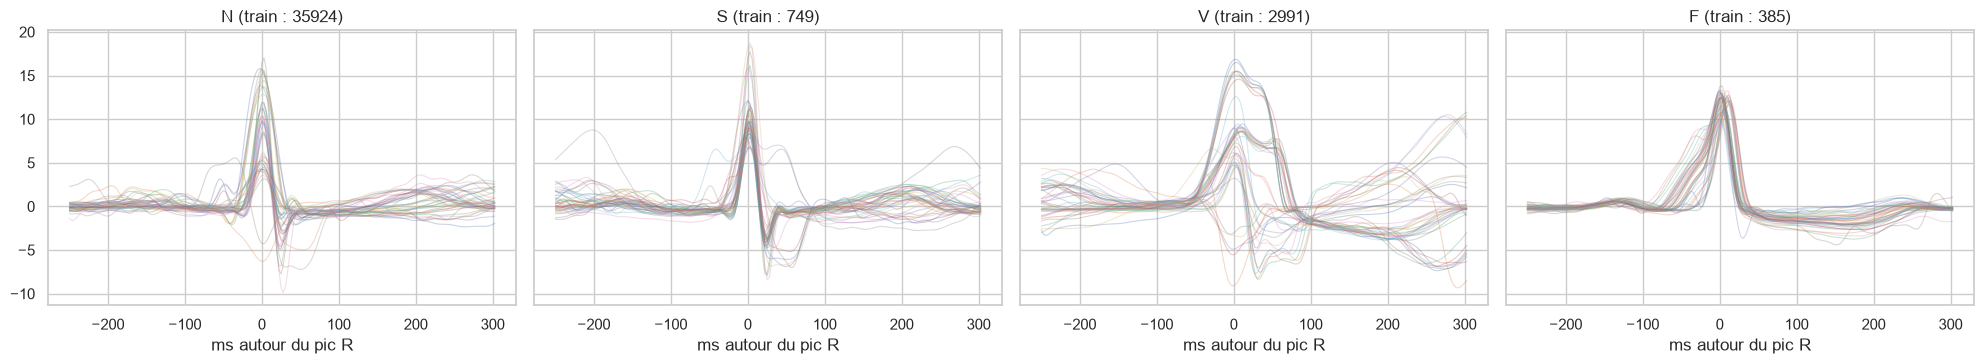

In [11]:
y, tr = d["y"], d["split"] == "train"
t_ms = np.arange(-CFG["window"]["pre"], CFG["window"]["post"]) / FS * 1000
rng = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, (i, cls) in zip(axes, enumerate(CFG["classes"])):
    idx = np.where(tr & (y == i))[0]
    for j in rng.choice(idx, size=min(40, len(idx)), replace=False):
        ax.plot(t_ms, X[j], alpha=0.3, lw=0.8)
    ax.set_title(f"{cls} (train : {len(idx)})"); ax.set_xlabel("ms autour du pic R")
plt.tight_layout(); fig.savefig(FIG_DIR / "dataset_gallery.png", dpi=150)

In [12]:
meta = pd.read_csv(PROJECT_ROOT / CFG["output"]["meta"], dtype={"record_id": str})
print(meta[meta.aami == "F"].groupby(["split", "record_id"]).size().sort_values(ascending=False).head(10))

split  record_id
train  208          372
test   213          362
val    223           14
       205           11
test   233           11
       210           10
train  124            5
val    114            4
test   200            2
train  108            2
dtype: int64


In [13]:
from src.preprocessing.rpeaks import qrs_energy
rid = "228"
x = filt(raw[rid]); _, mwi = qrs_energy(x, FS)
b = beats[beats.record_id == rid]
old_thr = 0.2 * np.percentile(mwi, 99.5)           # seuil de l'ancienne version
for cls, g in b.groupby("aami"):
    e = mwi[g["sample"].to_numpy()]
    print(f"{cls}: n={len(g):4d} | énergie médiane / ancien seuil = {np.median(e)/old_thr:6.2f} "
          f"| part sous le seuil = {100*(e < old_thr).mean():5.1f} %")

N: n=1688 | énergie médiane / ancien seuil =   0.63 | part sous le seuil =  97.9 %
S: n=   3 | énergie médiane / ancien seuil =   0.79 | part sous le seuil = 100.0 %
V: n= 362 | énergie médiane / ancien seuil =   4.24 | part sous le seuil =  12.2 %


In [14]:
from itertools import product
ds1_ids = [r for r in USABLE if r in DS1]
rows = []
for rel, fl in product([0.15, 0.2, 0.25, 0.35, 0.5], [0.015, 0.02, 0.03]):
    per = {}
    for rid in ds1_ids:
        ref = beats[beats.record_id == rid]["sample"].to_numpy()
        det = detect_r_peaks(filt(raw[rid]), FS, rel_thr=rel, floor_ratio=fl)
        per[rid] = evaluate_detection(ref, det, int(0.150 * FS))
    tp, fp, fn = (sum(v[i] for v in per.values()) for i in range(3))
    worst = min(100 * v[0] / max(v[0] + v[2], 1) for v in per.values())
    rows.append({"rel_thr": rel, "floor": fl, "sens_%": 100*tp/(tp+fn),
                 "ppv_%": 100*tp/(tp+fp), "F1_%": 100*2*tp/(2*tp+fp+fn),
                 "pire_record_sens_%": worst})
grid = pd.DataFrame(rows).sort_values("F1_%", ascending=False)
print(grid.round(2).head(8))

   rel_thr  floor  sens_%  ppv_%   F1_%  pire_record_sens_%
2     0.15   0.03   99.70  98.90  99.30               97.76
5     0.20   0.03   99.57  99.00  99.28               96.84
8     0.25   0.03   99.41  99.09  99.25               96.54
1     0.15   0.02   99.71  98.75  99.23               97.81
4     0.20   0.02   99.58  98.88  99.23               96.89
7     0.25   0.02   99.43  98.99  99.21               96.54
6     0.25   0.02   99.45  98.87  99.16               96.54
3     0.20   0.02   99.59  98.73  99.16               96.94


In [20]:
BEST = dict(rel_thr=0.15, floor_ratio=0.03)        # <- remplacez par votre choix (cellule 13)
res = []
for rid in USABLE:
    ref = beats[beats.record_id == rid]["sample"].to_numpy()
    tp, fp, fn = evaluate_detection(ref, detect_r_peaks(filt(raw[rid]), FS, **BEST), int(0.150 * FS))
    res.append({"record_id": rid, "split": "DS1" if rid in DS1 else "DS2", "TP": tp, "FP": fp, "FN": fn})
res = pd.DataFrame(res)
g = res.groupby("split")[["TP", "FP", "FN"]].sum()
g["sens_%"] = 100 * g.TP / (g.TP + g.FN); g["ppv_%"] = 100 * g.TP / (g.TP + g.FP)
print(g.round(2))
res["sens_%"] = 100 * res.TP / (res.TP + res.FN)
print(res.sort_values("sens_%").head(6).round(2))
res["ppv_%"] = 100 * res.TP / (res.TP + res.FP)
print(res.sort_values("ppv_%", ascending=False).head(6).round(2))  # records à plus de faux positifs

          TP    FP   FN  sens_%  ppv_%
split                                 
DS1    50869   565  152   99.70  98.90
DS2    49645  2813   67   99.87  94.64
   record_id split    TP  FP  FN  sens_%
21       201   DS1  1919  10  44   97.76
12       116   DS1  2389   3  23   99.05
23       203   DS1  2953  29  27   99.09
28       210   DS2  2629   9  21   99.21
26       208   DS1  2938  11  17   99.42
19       124   DS1  1611   0   8   99.51
   record_id split    TP  FP  FN  sens_%  ppv_%
0        100   DS2  2273   0   0  100.00  100.0
2        103   DS2  2083   0   1   99.95  100.0
11       115   DS1  1953   0   0  100.00  100.0
6        109   DS1  2527   0   5   99.80  100.0
10       114   DS1  1877   0   2   99.89  100.0
39       230   DS1  2256   0   0  100.00  100.0


In [16]:
rows = []
for rel, fl in product([0.10, 0.15, 0.20], [0.02, 0.03, 0.05, 0.08]):
    per = {}
    for rid in ds1_ids:
        ref = beats[beats.record_id == rid]["sample"].to_numpy()
        det = detect_r_peaks(filt(raw[rid]), FS, rel_thr=rel, floor_ratio=fl)
        per[rid] = evaluate_detection(ref, det, int(0.150 * FS))
    tp, fp, fn = (sum(v[i] for v in per.values()) for i in range(3))
    rows.append({"rel_thr": rel, "floor": fl, "sens_%": 100*tp/(tp+fn), "ppv_%": 100*tp/(tp+fp),
                 "F1_%": 100*2*tp/(2*tp+fp+fn),
                 "pire_record_sens_%": min(100*v[0]/max(v[0]+v[2], 1) for v in per.values())})
print(pd.DataFrame(rows).sort_values("F1_%", ascending=False).round(2).head(8))

    rel_thr  floor  sens_%  ppv_%   F1_%  pire_record_sens_%
7      0.15   0.08   99.46  99.50  99.48               97.15
6      0.15   0.05   99.66  99.25  99.45               97.71
11     0.20   0.08   99.39  99.51  99.45               96.84
10     0.20   0.05   99.54  99.28  99.41               96.84
3      0.10   0.08   99.53  99.21  99.37               97.15
5      0.15   0.03   99.70  98.90  99.30               97.76
2      0.10   0.05   99.75  98.85  99.29               98.76
9      0.20   0.03   99.57  99.00  99.28               96.84
